[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/05-deep-learning-llms/04_rnn.ipynb)

*Deep Learning & LLMs · Notebook 4 of 10*

# RNNs & Sequences

Models with memory: the RNN cell, unrolling over time, vanishing gradients, LSTM and GRU cells by hand, padding and masks, teacher forcing and preparing sequence data.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** An RNN reads like you do: one word at a time, carrying a running memory.

**What interviewers really test here:** Vanishing gradients, LSTM gates, padding masks and why transformers replaced them.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Why sequences need memory *(Basics)*
- [ ] 2. Unrolling: one sequence, step by step *(Basics)*
- [ ] 3. Training over time, by hand *(Core)*
- [ ] 4. Vanishing and exploding gradients *(Core)*
- [ ] 5. The LSTM cell, by hand *(Core)*
- [ ] 6. The GRU: fewer gates *(Core)*
- [ ] 7. Batches: padding, masks and masked loss *(Core)*
- [ ] 8. Sequence tasks and how to prepare data *(Advanced)*
- [ ] 9. RNNs in PyTorch, and why transformers replaced them *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### The three cells

| Cell | Update | Weight sets |
| --- | --- | --- |
| RNN | h = tanh(W\_h·h + W\_x·x + b) | 1 |
| GRU | h = (1 − u)·h + u·tanh(z) | 3 |
| LSTM | c = f·c + i·tanh(z); h = o·tanh(c) | 4 |



Parameters per set: d·h + h·h + h. Frameworks can differ slightly in how they count biases.

### Shapes to remember (batch first)

| Thing | Shape |
| --- | --- |
| Token ids | (N, T) |
| Embedded | (N, T, d) |
| All outputs | (N, T, h); (N, T, 2h) if bidirectional |
| Final state | (layers × directions, N, h) |
| Next-token scores | (N, T, vocab) |

### Common bugs

- Averaging the loss over padding positions.
- Taking the last column instead of the last *real* output.
- Forgetting `batch_first=True`.
- Shuffling a time series across the train/test boundary.
- Using a bidirectional model for next-token prediction, which lets it see the answer.
- Not clipping gradients. RNNs are especially prone to exploding.

---
# Part 2: Lessons, step by step

## Lesson 1: Why sequences need memory

*Level: Basics*

A dense network takes a fixed-size input and treats each position separately. Language doesn't work like that. Compare:



- "The dog bit the man."
- "The man bit the dog."



Same words, opposite meaning. Average the word vectors and these two sentences become identical, because an average forgets order. Sequences also vary in length: 3 words here, 3,000 there.



A **recurrent neural network** solves both problems with one idea: read one item at a time and keep a running summary, the **hidden state** h.



**hₜ = tanh(W\_h·hₜ₋₁ + W\_x·xₜ + b)**



The same weights are used at every step, just as a CNN reuses one filter across an image. So the number of parameters doesn't depend on sequence length.



**A single step by hand:** h = 0.5, x = 1, w\_h = 0.8, w\_x = 0.5, b = 0.1.



- Inside: 0.8·0.5 + 0.5·1 + 0.1 = 0.4 + 0.5 + 0.1 = 1.0.
- tanh(1.0) = **0.7616**. That's the new memory.



Why tanh? It keeps the state between −1 and 1, so it can't blow up however long the sequence is, and it lets values be positive or negative.

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q11](#q11). Try one now, or carry on and do them in Part 3.

## Lesson 2: Unrolling: one sequence, step by step

*Level: Basics*

Read 1, 0, −1 with w\_h = 0.5, w\_x = 1 and b = 0, starting from h = 0:



| t | x | Inside tanh | h |
| --- | --- | --- | --- |
| 1 | 1 | 0.5·0 + 1 = 1 | **0.7616** |
| 2 | 0 | 0.5·0.7616 + 0 = 0.3808 | **0.3634** |
| 3 | −1 | 0.5·0.3634 − 1 = −0.8183 | **−0.6741** |



Look at step 2. The input is 0, yet h isn't 0: the network remembers the earlier 1. That's the whole point of a hidden state.



**Unrolling** means drawing one copy of the cell per time step. It's still one set of weights, but seeing it as a long chain shows two things: why you can't run the steps in parallel (each needs the previous one), and how gradients have to flow back through every copy.



**Size of the cell:** for input size d and hidden size h, an RNN has d·h + h·h + h parameters. With d = 64, h = 128: 8,192 + 16,384 + 128 = **24,704**, whether the sequence has 5 or 5,000 steps.

**✏️ Your turn:** you now have what you need for [Q2](#q2), [Q3](#q3). Try one now, or carry on and do them in Part 3.

## Lesson 3: Training over time, by hand

*Level: Core*

Training an RNN uses ordinary backpropagation on the unrolled chain, called **backpropagation through time** (BPTT).



Take a simplified RNN with no tanh: hₜ = w·hₜ₋₁ + xₜ. With w = 0.5 and xs = 1, 2, 3, the loss is the final state.



- h₁ = 1
- h₂ = 0.5·1 + 2 = 2.5
- h₃ = 0.5·2.5 + 3 = **4.25**



Written out, h₃ = w²·1 + w·2 + 3. Its derivative is 2w·1 + 2 = 2·0.5 + 2 = **3**.



You can get this without the algebra, by tracking d = dh/dw alongside h. The update comes from the product rule: **d ← hₜ₋₁ + w·d**.



| t | d | h |
| --- | --- | --- |
| 1 | 0 + 0.5·0 = 0 | 1 |
| 2 | 1 + 0.5·0 = 1 | 2.5 |
| 3 | 2.5 + 0.5·1 = **3** | 4.25 |



The chart uses this exact gradient. Data comes from a hidden w = 0.8. We start at w = 0.1, and gradient descent finds it.



**Long sequences:** BPTT must store every step, and that's expensive. **Truncated BPTT** cuts a long sequence into chunks and backpropagates only within each one, keeping the hidden state between chunks. It's cheaper, but can't directly learn links longer than a chunk.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

final w: 0.8


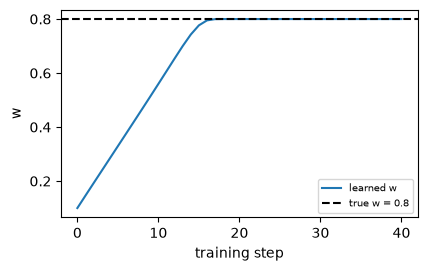

In [2]:
def learn_recurrent_weight():
    rng = np.random.default_rng(0)
    data = rng.normal(size=(64, 12))
    true_w, w, lr = 0.8, 0.1, 0.02

    def final_state(weight, xs):
        h = 0.0
        for x in xs:
            h = weight * h + x
        return h

    targets = [final_state(true_w, xs) for xs in data]
    history = [w]
    for _ in range(40):
        grad = 0.0
        for xs, y in zip(data, targets):
            h, d = 0.0, 0.0
            for x in xs:
                d = h + w * d
                h = w * h + x
            grad += 2 * (h - y) * d
        w -= lr * grad / len(data)
        history.append(w)
    print("final w:", round(w, 4))
    fig, ax = plt.subplots(figsize=(4.6, 2.7))
    ax.plot(history, label="learned w")
    ax.axhline(true_w, color="black", linestyle="--", label="true w = 0.8")
    ax.set_xlabel("training step")
    ax.set_ylabel("w")
    ax.legend(fontsize=7)


learn_recurrent_weight()

**✏️ Your turn:** you now have what you need for [Q18](#q18), [Q16](#q16). Try one now, or carry on and do them in Part 3.

## Lesson 4: Vanishing and exploding gradients

*Level: Core*

In the derivative above, an old input is multiplied by w once per step it has travelled. In general, the influence of something t steps ago scales roughly like wᵗ:



| w | t = 1 | t = 10 | t = 50 | Problem |
| --- | --- | --- | --- | --- |
| 0.9 | 0.9 | 0.349 | **0.005** | vanishes |
| 1.0 | 1 | 1 | 1 | stable, but a knife edge |
| 1.1 | 1.1 | 2.594 | **117.4** | explodes |



So a small change in w turns "forgets everything" into "numbers blow up". Tanh makes vanishing more likely still, since its slope is at most 1.



What this means in practice: in "*The keys* to the old wooden cabinet in the hall *are* missing", the verb depends on a word far back. By the time the gradient arrives, it's nearly zero, so the network struggles to learn that link.



- **Exploding** gradients have a simple fix: clip them (the training topic covers this).
- **Vanishing** gradients need a better architecture. That's why LSTMs exist.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

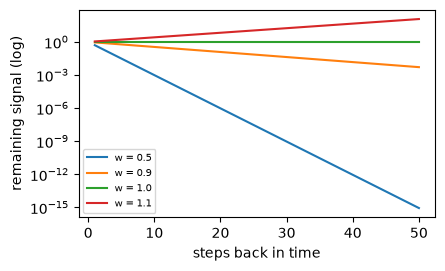

In [3]:
def fading_signal():
    t = np.arange(1, 51)
    fig, ax = plt.subplots(figsize=(4.6, 2.7))
    for w in [0.5, 0.9, 1.0, 1.1]:
        ax.semilogy(t, float(w) ** t, label=f"w = {w}")
    ax.set_xlabel("steps back in time")
    ax.set_ylabel("remaining signal (log)")
    ax.legend(fontsize=7)


fading_signal()

**✏️ Your turn:** you now have what you need for [Q4](#q4). Try one now, or carry on and do them in Part 3.

## Lesson 5: The LSTM cell, by hand

*Level: Core*

An LSTM adds a second memory, the **cell state** c, and three learned **gates**. A gate is a sigmoid between 0 (closed) and 1 (open).



| Gate | Question it answers | Equation |
| --- | --- | --- |
| Forget f | How much old memory to keep? | c ← **f**·c + … |
| Input i | How much new information to add? | … + **i**·tanh(z) |
| Output o | How much to reveal now? | h = **o**·tanh(c) |



Each gate has the same form: σ(w\_h·h + w\_x·x + b). With h = 0.5, x = 1, w\_h = w\_x = 1, b = 0, the inside is 1.5, so the gate is σ(1.5) = **0.8176**. Applied to c = 2, it keeps 1.6351.



**A full step:** f = 0.9, i = 0.2, o = 0.5, z = 1, c = 2.



1. Keep: 0.9·2 = 1.8.
2. Add: 0.2·tanh(1) = 0.2·0.7616 = 0.1523.
3. New c = 1.8 + 0.1523 = **1.9523**.
4. Output: h = 0.5·tanh(1.9523) = **0.4802**.



**Why it survives:** the cell state update is mostly *addition*. Instead of being forced through a multiply-and-squash at every step, c passes along almost unchanged when f ≈ 1. Compare 20 steps: an RNN with w = 0.5 keeps 0.5²⁰ ≈ 0.000001; a cell with f = 0.99 keeps 0.99²⁰ ≈ **0.818**.



That's the same idea as a residual connection, arriving almost two decades earlier: a direct path for the signal. Networks often initialise the forget gate's bias to a positive value so it starts open.



**Cost:** 4 sets of weights (three gates and the candidate), so 4 times the RNN's parameters: 4 × 24,704 = 98,816 for d = 64, h = 128. PyTorch's `nn.LSTM` reports slightly more, 99,328, because it keeps two bias vectors per set.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

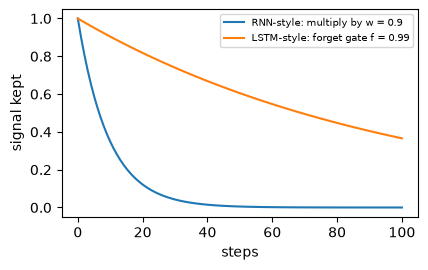

In [4]:
def rnn_vs_lstm_memory():
    steps = np.arange(0, 101)
    fig, ax = plt.subplots(figsize=(4.6, 2.7))
    ax.plot(steps, 0.9 ** steps, label="RNN-style: multiply by w = 0.9")
    ax.plot(steps, 0.99 ** steps, label="LSTM-style: forget gate f = 0.99")
    ax.set_xlabel("steps")
    ax.set_ylabel("signal kept")
    ax.legend(fontsize=7)


rnn_vs_lstm_memory()

**✏️ Your turn:** you now have what you need for [Q5](#q5), [Q19](#q19), [Q12](#q12). Try one now, or carry on and do them in Part 3.

## Lesson 6: The GRU: fewer gates

*Level: Core*

A GRU merges the cell state and hidden state, and uses a single **update gate** u to blend old with new:



**hₜ = (1 − u)·hₜ₋₁ + u·tanh(z)**



(The full GRU also has a reset gate, which shapes the candidate z. So 3 sets of weights in all.)



With h = 0.2 and z = 1, so tanh(z) = 0.7616:



| u | Calculation | New h | Meaning |
| --- | --- | --- | --- |
| 0 | 1·0.2 + 0·0.7616 | 0.2 | keep the old memory unchanged |
| 0.5 | 0.5·0.2 + 0.5·0.7616 | **0.4808** | half and half |
| 1 | 0·0.2 + 1·0.7616 | 0.7616 | replace it entirely |



|   | RNN | GRU | LSTM |
| --- | --- | --- | --- |
| Sets of weights | 1 | 3 | 4 |
| Parameters (d = 10, h = 20) | 620 | 1,860 | 2,480 |
| Long memory | poor | good | good |



GRU and LSTM usually perform about the same. If the choice matters for your task, test both on your data.

**✏️ Your turn:** you now have what you need for [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 7: Batches: padding, masks and masked loss

*Level: Core*

Tensors must be rectangular, but sentences aren't. So you **pad** short ones with a special token, and keep a **mask** saying which positions are real:



```python
[[5, 2, 9],        mask  [[1, 1, 1],
 [7, 0, 0],               [1, 0, 0],
 [3, 3, 0]]               [1, 1, 0]]
```



Padding is a tensor-shape requirement and carries no meaning, so it must not affect anything. Three places commonly go wrong:



**1. The loss.** Per-position losses are [1, 2, ~~9~~] and [3, ~~9~~, ~~9~~]. Crossed-out values are padding.



- Wrong (all values): 33 / 6 = **5.5**.
- Right (masked): (1 + 2 + 3) / 3 = **2**.



Note the division is by the number of *real* positions, not the table size. Otherwise short sequences shrink the loss for no good reason.



**2. The final state.** The usual summary of a sequence is its output at the last real step. With outputs [1,2,3], [4,5,6], [7,8,9] and lengths 3, 1, 2, that's 3, 4 and 8. Taking the last column instead would give 3, 6, 9: two of those came from padding.



**3. Averaging.** Mean pooling over [1,2], [3,4] and a padding row [100,100] must give [2, 3], and not include the 100s.



**Efficiency tip:** sort or bucket by length so similar lengths share a batch; there's less wasted padding.

**✏️ Your turn:** you now have what you need for [Q6](#q6), [Q7](#q7), [Q13](#q13), [Q14](#q14), [Q17](#q17). Try one now, or carry on and do them in Part 3.

## Lesson 8: Sequence tasks and how to prepare data

*Level: Advanced*

**Predicting the next item** is the single most important setup in this course. Every language model trains this way. For tokens [5, 8, 2, 9]:



| Input | 5 | 8 | 2 |
| --- | --- | --- | --- |
| Target | 8 | 2 | 9 |



Shift by one, and each position becomes a training example. During training, the input at each step is the *true* previous token, even if the model got the last one wrong. That's **teacher forcing**. It trains faster, but at prediction time the model only has its own outputs to go on, so errors can snowball.



**Forecasting** a number series uses a sliding window. With 1, 2, 3, 4, 5 and window 2: X = [1,2], [2,3], [3,4] and y = 3, 4, 5. For a time series, split by time and never shuffle across the split.



**Text to numbers:** "hello" has characters e, h, l, o, numbered 0, 1, 2, 3, so it encodes to [1, 0, 2, 2, 3]. Real tokenisers are the next topic.



**Bidirectional RNNs** read both ways and join the two states. This helps tagging ("Apple" as a company depends on later words), but can't work when predicting the next token: the future isn't available. For 1, 0, −1 the first position gets forward state 0.7616 and backward state 0.6741. The second number was computed from the whole sequence read in reverse, so it carries information about what comes later.



| Task | Shape | Uses |
| --- | --- | --- |
| Many-to-one | sequence → label | last state or mean pooling |
| Many-to-many | sequence → one output per step | all states |
| Seq-to-seq | sequence → different sequence | encoder + decoder (the problem attention was invented for) |

**✏️ Your turn:** you now have what you need for [Q9](#q9), [Q8](#q8), [Q10](#q10), [Q15](#q15). Try one now, or carry on and do them in Part 3.

## Lesson 9: RNNs in PyTorch, and why transformers replaced them

*Level: Advanced*

```python
import torch, torch.nn as nn

emb = nn.Embedding(1000, 64)
lstm = nn.LSTM(64, 128, batch_first=True)
head = nn.Linear(128, 1000)

tokens = torch.randint(0, 1000, (8, 20))    # (batch, time)
output, (h, c) = lstm(emb(tokens))
print(output.shape)   # (8, 20, 128): one state per step
print(h.shape)        # (1, 8, 128): (layers, batch, hidden)
logits = head(output) # (8, 20, 1000): next-token scores
```



Shape mistake to watch for: without `batch_first=True`, PyTorch expects (time, batch, features). It won't raise an error if your numbers happen to fit, and it will silently read the data the wrong way round.



**Why did transformers take over language?**



|   | RNN | Transformer |
| --- | --- | --- |
| Processing | one step at a time | all positions in parallel |
| A word 1,000 steps back | must pass through 1,000 updates | one direct attention link |
| Summary of input | squeezed into a fixed-size state | can look back at everything |
| Cost per token | constant memory | grows with context length |



RNNs are still a reasonable choice for small on-device models and streaming signals, where constant memory matters.



The PyTorch code here is shown as text. PyTorch doesn't run in this site's browser IDE, so the practice questions use NumPy and plain Python.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

<a id="q1"></a>
### Q1. One RNN Step

🟢 Warm-up · *New memory from old memory*

Scalars: return tanh(w\_h·h + w\_x·x + b), rounded to 4 decimals.

**Examples**

- `h = 0.5, x = 1.0, w_h = 0.8, w_x = 0.5, b = 0.1` → `0.7616`
- `h = 0.0, x = 2.0, w_h = 0.8, w_x = 0.5, b = 0.0` → `0.7616`

In [ ]:
def rnn_step(h, x, w_h, w_x, b):
    """
    Scalars: return tanh(w_h·h + w_x·x + b), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(rnn_step, [
    ((0.5, 1.0, 0.8, 0.5, 0.1), 0.7616),
    ((0.0, 2.0, 0.8, 0.5, 0.0), 0.7616),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute inside, then tanh with exponentials.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.tanh`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Compute inside, then tanh with exponentials.

```python
def rnn_step(h, x, w_h, w_x, b):
    z = w_h * h + w_x * x + b
    return round((math.exp(z) - math.exp(-z)) / (math.exp(z) + math.exp(-z)), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.tanh`.

```python
def rnn_step(h, x, w_h, w_x, b):
    return round(float(np.tanh(w_h * h + w_x * x + b)), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute inside, then tanh with exponentials. That costs O(1) time and O(1) space."

"I can do better: `np.tanh`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rnn/one-rnn-step)

<a id="q2"></a>
### Q2. Run an RNN Over a Sequence

🟢 Warm-up · *Unrolling*

Start with h = 0 and return all hidden states, rounded to 4 decimals (b = 0).

**Examples**

- `xs = [1.0, 0.0, -1.0], w_h = 0.5, w_x = 1.0` → `[0.7616, 0.3634, -0.6741]`

In [ ]:
def rnn_run(xs, w_h, w_x):
    """
    Start with h = 0 and return all hidden states, rounded to 4 decimals (b =
    0).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(rnn_run, [
    (([1.0, 0.0, -1.0], 0.5, 1.0), [0.7616, 0.3634, -0.6741]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop with exponentials for tanh.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A loop with `np.tanh`; each step needs the previous one, so it can't be fully vectorised.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** A loop with exponentials for tanh.

```python
def rnn_run(xs, w_h, w_x):
    h, out = 0.0, []
    for x in xs:
        h = math.tanh(w_h * h + w_x * x)
        out.append(round(h, 4))
    return out
```

**Cost:** O(T) time, O(T) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A loop with `np.tanh`; each step needs the previous one, so it can't be fully vectorised.

```python
def rnn_run(xs, w_h, w_x):
    h, out = 0.0, np.zeros(len(xs))
    for t, x in enumerate(xs):
        h = np.tanh(w_h * h + w_x * x)
        out[t] = h
    return out.round(4)
```

**Cost:** O(T) time, O(T) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop with exponentials for tanh. That costs O(T) time and O(T) space."

"I can do better: A loop with `np.tanh`; each step needs the previous one, so it can't be fully vectorised. That's O(T) time and O(T) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rnn/run-an-rnn-over-a-sequence)

<a id="q3"></a>
### Q3. Parameters: RNN, GRU, LSTM

🟢 Warm-up · *3, then 4 gates' worth*

For input size d and hidden size h, a cell has k·(d·h + h·h + h) parameters, with k = 1 (RNN), 3 (GRU), 4 (LSTM). Return all three as a tuple.

**Examples**

- `d = 64, h = 128` → `(24704, 74112, 98816)`
- `d = 10, h = 20` → `(620, 1860, 2480)`

In [ ]:
def cell_params(d, h):
    """
    For input size d and hidden size h, a cell has k·(d·h + h·h + h) parameters,
    with k = 1 (RNN), 3 (GRU), 4 (LSTM). Return all three as a tuple.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(cell_params, [
    ((64, 128), (24704, 74112, 98816)),
    ((10, 20), (620, 1860, 2480)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute one block, then multiply three times.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised over k.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Compute one block, then multiply three times.

```python
def cell_params(d, h):
    one = d * h + h * h + h
    return (one, 3 * one, 4 * one)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Vectorised over k.

```python
def cell_params(d, h):
    return tuple((np.array([1, 3, 4]) * (d * h + h * h + h)).tolist())
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute one block, then multiply three times. That costs O(1) time and O(1) space."

"I can do better: Vectorised over k. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rnn/parameters-rnn-gru-lstm)

<a id="q4"></a>
### Q4. How Gradients Fade Through Time

🟢 Warm-up · *wᵗ*

A signal passes through t steps, multiplied by w each time. Return the size left for each t in ts, rounded to 6 decimals.

**Examples**

- `w = 0.9, ts = [1, 10, 50]` → `[0.9, 0.3487, 0.0052]`
- `w = 1.1, ts = [1, 10, 50]` → `[1.1, 2.5937, 117.3909]`

In [ ]:
def fade(w, ts):
    """
    A signal passes through t steps, multiplied by w each time. Return the size
    left for each t in ts, rounded to 6 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(fade, [
    ((0.9, [1, 10, 50]), [0.9, 0.3487, 0.0052]),
    ((1.1, [1, 10, 50]), [1.1, 2.5937, 117.3909]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply in a loop for each t.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`w ** np.array(ts)`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Multiply in a loop for each t.

```python
def fade(w, ts):
    out = []
    for t in ts:
        v = 1.0
        for _ in range(t):
            v *= w
        out.append(round(v, 6))
    return out
```

**Cost:** O(k·T) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `w ** np.array(ts)`.

```python
def fade(w, ts):
    return (float(w) ** np.array(ts)).round(6)
```

**Cost:** O(k) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply in a loop for each t. That costs O(k·T) time and O(k) space."

"I can do better: `w ** np.array(ts)`. That's O(k) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rnn/how-gradients-fade-through-time)

<a id="q5"></a>
### Q5. An LSTM Gate

🟢 Warm-up · *A soft on/off switch*

A gate is σ(w\_h·h + w\_x·x + b). Return the gate value, and the kept part of c (gate × c), both rounded to 4 decimals.

**Examples**

- `h = 0.5, x = 1.0, w_h = 1.0, w_x = 1.0, b = 0.0, c = 2.0` → `(0.8176, 1.6351)`
- `h = 0.5, x = 1.0, w_h = -3.0, w_x = -3.0, b = 0.0, c = 2.0` → `(0.011, 0.022)`

In [ ]:
def lstm_gate(h, x, w_h, w_x, b, c):
    """
    A gate is σ(w_h·h + w_x·x + b). Return the gate value, and the kept part of
    c (gate × c), both rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(lstm_gate, [
    ((0.5, 1.0, 1.0, 1.0, 0.0, 2.0), (0.8176, 1.6351)),
    ((0.5, 1.0, -3.0, -3.0, 0.0, 2.0), (0.011, 0.022)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sigmoid with `math.exp`.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.exp`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Sigmoid with `math.exp`.

```python
def lstm_gate(h, x, w_h, w_x, b, c):
    g = 1 / (1 + math.exp(-(w_h * h + w_x * x + b)))
    return (round(g, 4), round(g * c, 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.exp`.

```python
def lstm_gate(h, x, w_h, w_x, b, c):
    g = 1 / (1 + np.exp(-(w_h * h + w_x * x + b)))
    return (round(float(g), 4), round(float(g * c), 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sigmoid with `math.exp`. That costs O(1) time and O(1) space."

"I can do better: `np.exp`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rnn/an-lstm-gate)

<a id="q6"></a>
### Q6. Pad a Batch of Sequences

🟢 Warm-up · *Same length for a tensor*

Pad each list on the right with 0 up to the longest length.

**Examples**

- `seqs = [[5, 2, 9], [7], [3, 3]]` → `[[5, 2, 9], [7, 0, 0], [3, 3, 0]]`

In [ ]:
def pad(seqs):
    """
    Pad each list on the right with 0 up to the longest length.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(pad, [
    (([[5, 2, 9], [7], [3, 3]],), [[5, 2, 9], [7, 0, 0], [3, 3, 0]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add zeros in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Fill a zero matrix.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Add zeros in a loop.

```python
def pad(seqs):
    longest = max(len(s) for s in seqs)
    return [s + [0] * (longest - len(s)) for s in seqs]
```

**Cost:** O(n·T) time, O(n·T) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Fill a zero matrix.

```python
def pad(seqs):
    out = np.zeros((len(seqs), max(map(len, seqs))), dtype=int)
    for i, s in enumerate(seqs):
        out[i, :len(s)] = s
    return out
```

**Cost:** O(n·T) time, O(n·T) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add zeros in a loop. That costs O(n·T) time and O(n·T) space."

"I can do better: Fill a zero matrix. That's O(n·T) time and O(n·T) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rnn/pad-a-batch-of-sequences)

<a id="q7"></a>
### Q7. Mask From Lengths

🟢 Warm-up · *1 for real, 0 for padding*

Return a 0/1 matrix with lengths[i] ones in row i, then zeros, up to the longest length.

**Examples**

- `lengths = [3, 1, 2]` → `[[1, 1, 1], [1, 0, 0], [1, 1, 0]]`

In [ ]:
def mask_from_lengths(lengths):
    """
    Return a 0/1 matrix with lengths[i] ones in row i, then zeros, up to the
    longest length.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(mask_from_lengths, [
    (([3, 1, 2],), [[1, 1, 1], [1, 0, 0], [1, 1, 0]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Build each row in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Compare `np.arange(T)` with lengths[:, None].

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Build each row in a loop.

```python
def mask_from_lengths(lengths):
    T = max(lengths)
    return [[1] * n + [0] * (T - n) for n in lengths]
```

**Cost:** O(n·T) time, O(n·T) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Compare `np.arange(T)` with lengths[:, None].

```python
def mask_from_lengths(lengths):
    n = np.array(lengths)
    return (np.arange(n.max()) < n[:, None]).astype(int)
```

**Cost:** O(n·T) time, O(n·T) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Build each row in a loop. That costs O(n·T) time and O(n·T) space."

"I can do better: Compare `np.arange(T)` with lengths[:, None]. That's O(n·T) time and O(n·T) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rnn/mask-from-lengths)

<a id="q8"></a>
### Q8. Sliding Windows for Forecasting

🟢 Warm-up · *Turning a series into examples*

Return (X, y): each X row holds n consecutive values and y is the value after them.

**Examples**

- `series = [1, 2, 3, 4, 5], n = 2` → `([[1, 2], [2, 3], [3, 4]], [3, 4, 5])`

In [ ]:
def windows(series, n):
    """
    Return (X, y): each X row holds n consecutive values and y is the value
    after them.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(windows, [
    (([1, 2, 3, 4, 5], 2), ([[1, 2], [2, 3], [3, 4]], [3, 4, 5])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over start positions.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sliding_window_view`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loop over start positions.

```python
def windows(series, n):
    X, y = [], []
    for i in range(len(series) - n):
        X.append(series[i:i + n])
        y.append(series[i + n])
    return (X, y)
```

**Cost:** O(T·n) time, O(T·n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `sliding_window_view`.

```python
def windows(series, n):
    s = np.array(series)
    return (np.lib.stride_tricks.sliding_window_view(s, n)[:-1], s[n:])
```

**Cost:** O(T·n) time, O(T·n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over start positions. That costs O(T·n) time and O(T·n) space."

"I can do better: `sliding_window_view`. That's O(T·n) time and O(T·n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rnn/sliding-windows-for-forecasting)

<a id="q9"></a>
### Q9. Teacher Forcing Targets

🟢 Warm-up · *Predict the next token*

For a token list, return (inputs, targets): inputs drop the last, targets drop the first. Every language model is trained like this.

**Examples**

- `tokens = [5, 8, 2, 9]` → `([5, 8, 2], [8, 2, 9])`

In [ ]:
def shift(tokens):
    """
    For a token list, return (inputs, targets): inputs drop the last, targets
    drop the first. Every language model is trained like this.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(shift, [
    (([5, 8, 2, 9],), ([5, 8, 2], [8, 2, 9])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Slices of a list.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Slices of an array, which works on whole batches with `[:, :-1]`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Slices of a list.

```python
def shift(tokens):
    return (tokens[:-1], tokens[1:])
```

**Cost:** O(T) time, O(T) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Slices of an array, which works on whole batches with `[:, :-1]`.

```python
def shift(tokens):
    t = np.array(tokens)
    return (t[:-1], t[1:])
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Slices of a list. That costs O(T) time and O(T) space."

"I can do better: Slices of an array, which works on whole batches with `[:, :-1]`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rnn/teacher-forcing-targets)

<a id="q10"></a>
### Q10. Encode, Decode With a Vocabulary

🟢 Warm-up · *Text ↔ numbers*

Build a character vocabulary from text (sorted unique characters). Return (ids of the text, the text decoded back).

**Examples**

- `text = 'hello'` → `([1, 0, 2, 2, 3], 'hello')`

In [ ]:
def encode_decode(text):
    """
    Build a character vocabulary from text (sorted unique characters). Return
    (ids of the text, the text decoded back).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(encode_decode, [
    (('hello',), ([1, 0, 2, 2, 3], 'hello')),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Dictionaries both ways.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.unique(..., return_inverse=True)` gives both directly.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Dictionaries both ways.

```python
def encode_decode(text):
    chars = sorted(set(text))
    to_id = {c: i for i, c in enumerate(chars)}
    ids = [to_id[c] for c in text]
    return (ids, "".join(chars[i] for i in ids))
```

**Cost:** O(n log n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.unique(..., return_inverse=True)` gives both directly.

```python
def encode_decode(text):
    chars, ids = np.unique(list(text), return_inverse=True)
    return (ids.ravel(), "".join(chars[ids.ravel()]))
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Dictionaries both ways. That costs O(n log n) time and O(k) space."

"I can do better: `np.unique(..., return_inverse=True)` gives both directly. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rnn/encode-decode-with-a-vocabulary)

<a id="q11"></a>
### Q11. A Vector RNN Step

🟡 Interview standard · *With matrices*

Return tanh(h·Wh + x·Wx + b), rounded to 4 decimals.

**Examples**

- `h = [0.5, -0.5], x = [1.0], Wh = [[0.5, 0.0], [0.0, 0.5]], Wx = [[1.0, -1.0]], b = [0.0, 0.1]` → `[0.8483, -0.8178]`

In [ ]:
def rnn_vector(h, x, Wh, Wx, b):
    """
    Return tanh(h·Wh + x·Wx + b), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(rnn_vector, [
    (([0.5, -0.5], [1.0], [[0.5, 0.0], [0.0, 0.5]], [[1.0, -1.0]], [0.0, 0.1]), [0.8483, -0.8178]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loops for each matrix product.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Matrix products with `@`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loops for each matrix product.

```python
def rnn_vector(h, x, Wh, Wx, b):
    out = []
    for k in range(len(b)):
        z = b[k]
        z += sum(h[i] * Wh[i][k] for i in range(len(h)))
        z += sum(x[i] * Wx[i][k] for i in range(len(x)))
        out.append(round(math.tanh(z), 4))
    return out
```

**Cost:** O(h²) time, O(h) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Matrix products with `@`.

```python
def rnn_vector(h, x, Wh, Wx, b):
    return np.tanh(np.array(h) @ np.array(Wh) + np.array(x) @ np.array(Wx) + np.array(b)).round(4)
```

**Cost:** O(h²) time, O(h) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loops for each matrix product. That costs O(h²) time and O(h) space."

"I can do better: Matrix products with `@`. That's O(h²) time and O(h) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rnn/a-vector-rnn-step)

<a id="q12"></a>
### Q12. Memory Across Many Steps

🟡 Interview standard · *Why the cell state survives*

After T steps, an RNN's signal is ∏ w and an LSTM's is ∏ f. Return (w^T, f^T), rounded to 6 decimals.

**Examples**

- `w = 0.5, f = 0.99, T = 20` → `(0.0, 0.8179)`
- `w = 0.9, f = 0.99, T = 100` → `(0.0, 0.366)`

In [ ]:
def memory_compare(w, f, T):
    """
    After T steps, an RNN's signal is ∏ w and an LSTM's is ∏ f. Return (w^T,
    f^T), rounded to 6 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(memory_compare, [
    ((0.5, 0.99, 20), (0.0, 0.8179)),
    ((0.9, 0.99, 100), (0.0, 0.366)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Powers.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Multiply in a loop.

```python
def memory_compare(w, f, T):
    a = b = 1.0
    for _ in range(T):
        a *= w
        b *= f
    return (round(a, 6), round(b, 6))
```

**Cost:** O(T) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Powers.

```python
def memory_compare(w, f, T):
    return (round(w ** T, 6), round(f ** T, 6))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply in a loop. That costs O(T) time and O(1) space."

"I can do better: Powers. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rnn/memory-across-many-steps)

<a id="q13"></a>
### Q13. Masked Average Loss

🟡 Interview standard · *Ignore padding*

Average per-position losses only where the mask is 1, rounded to 4 decimals.

**Examples**

- `loss = [[1.0, 2.0, 9.0], [3.0, 9.0, 9.0]], mask = [[1, 1, 0], [1, 0, 0]]` → `2.0`

In [ ]:
def masked_loss(loss, mask):
    """
    Average per-position losses only where the mask is 1, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(masked_loss, [
    (([[1.0, 2.0, 9.0], [3.0, 9.0, 9.0]], [[1, 1, 0], [1, 0, 0]]), 2.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add up masked losses and count them.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`(loss * mask).sum() / mask.sum()`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Add up masked losses and count them.

```python
def masked_loss(loss, mask):
    total, count = 0.0, 0
    for r1, r2 in zip(loss, mask):
        for l, m in zip(r1, r2):
            if m:
                total += l
                count += 1
    return round(total / count, 4)
```

**Cost:** O(n·T) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `(loss * mask).sum() / mask.sum()`.

```python
def masked_loss(loss, mask):
    loss, mask = np.array(loss), np.array(mask)
    return round((loss * mask).sum() / mask.sum(), 4)
```

**Cost:** O(n·T) time, O(n·T) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add up masked losses and count them. That costs O(n·T) time and O(1) space."

"I can do better: `(loss * mask).sum() / mask.sum()`. That's O(n·T) time and O(n·T) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rnn/masked-average-loss)

<a id="q14"></a>
### Q14. Last Real Output of Each Sequence

🟡 Interview standard · *Not the padding*

outputs is a table with one row per sequence, one value per step. Return each sequence's output at its last real position.

**Examples**

- `outputs = [[1, 2, 3], [4, 5, 6], [7, 8, 9]], lengths = [3, 1, 2]` → `[3, 4, 8]`

In [ ]:
def last_real(outputs, lengths):
    """
    outputs is a table with one row per sequence, one value per step. Return
    each sequence's output at its last real position.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(last_real, [
    (([[1, 2, 3], [4, 5, 6], [7, 8, 9]], [3, 1, 2]), [3, 4, 8]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop with index lengths[i] − 1.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`outputs[np.arange(n), lengths - 1]`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loop with index lengths[i] − 1.

```python
def last_real(outputs, lengths):
    return [row[n - 1] for row, n in zip(outputs, lengths)]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `outputs[np.arange(n), lengths - 1]`.

```python
def last_real(outputs, lengths):
    o, n = np.array(outputs), np.array(lengths)
    return o[np.arange(len(o)), n - 1]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop with index lengths[i] − 1. That costs O(n) time and O(n) space."

"I can do better: `outputs[np.arange(n), lengths - 1]`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rnn/last-real-output-of-each-sequence)

<a id="q15"></a>
### Q15. Bidirectional States

🟡 Interview standard · *Read both ways*

Run a scalar RNN (h = tanh(0.5h + x)) forward and backward over xs. Return per-position pairs (forward h, backward h), rounded to 4 decimals.

**Examples**

- `xs = [1.0, 0.0, -1.0]` → `[[0.7616, 0.6741], [0.3634, -0.3634], [-0.6741, -0.7616]]`

In [ ]:
def bidirectional(xs):
    """
    Run a scalar RNN (h = tanh(0.5h + x)) forward and backward over xs. Return
    per-position pairs (forward h, backward h), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bidirectional, [
    (([1.0, 0.0, -1.0],), [[0.7616, 0.6741], [0.3634, -0.3634], [-0.6741, -0.7616]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Two loops, reversing the second's output.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A helper run twice with NumPy, then `np.column_stack`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Two loops, reversing the second's output.

```python
def bidirectional(xs):
    h, forward = 0.0, []
    for x in xs:
        h = math.tanh(0.5 * h + x)
        forward.append(h)
    h, backward = 0.0, []
    for x in reversed(xs):
        h = math.tanh(0.5 * h + x)
        backward.append(h)
    backward.reverse()
    return [[round(a, 4), round(b, 4)] for a, b in zip(forward, backward)]
```

**Cost:** O(T) time, O(T) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A helper run twice with NumPy, then `np.column_stack`.

```python
def bidirectional(xs):
    def run(values):
        out, h = [], 0.0
        for x in values:
            h = np.tanh(0.5 * h + x)
            out.append(h)
        return np.array(out)
    return np.column_stack([run(xs), run(xs[::-1])[::-1]]).round(4)
```

**Cost:** O(T) time, O(T) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Two loops, reversing the second's output. That costs O(T) time and O(T) space."

"I can do better: A helper run twice with NumPy, then `np.column_stack`. That's O(T) time and O(T) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `xs = [1.0, 0.0, -1.0]`

1. run() returns array([ 0.76159416,  0.36339948, -0.6...
2. run() returns array([-0.76159416, -0.36339948,  0.6...
3. bidirectional() returns array([[ 0.7616,  0.6741],
       [ 0...

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rnn/bidirectional-states)

<a id="q16"></a>
### Q16. Truncated BPTT Chunks

🟡 Interview standard · *Long sequences in pieces*

Split the sequence into chunks of size k; drop a short leftover. Return the chunks.

**Examples**

- `seq = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], k = 3` → `[[0, 1, 2], [3, 4, 5], [6, 7, 8]]`
- `seq = [1, 2, 3, 4], k = 2` → `[[1, 2], [3, 4]]`

In [ ]:
def chunks(seq, k):
    """
    Split the sequence into chunks of size k; drop a short leftover. Return the
    chunks.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(chunks, [
    (([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], 3), [[0, 1, 2], [3, 4, 5], [6, 7, 8]]),
    (([1, 2, 3, 4], 2), [[1, 2], [3, 4]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Step through with slices.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Trim, then `reshape(-1, k)`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Step through with slices.

```python
def chunks(seq, k):
    return [seq[i:i + k] for i in range(0, len(seq) - k + 1, k)]
```

**Cost:** O(T) time, O(T) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Trim, then `reshape(-1, k)`.

```python
def chunks(seq, k):
    s = np.array(seq)
    return s[:len(s) // k * k].reshape(-1, k)
```

**Cost:** O(T) time, O(1) view space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Step through with slices. That costs O(T) time and O(T) space."

"I can do better: Trim, then `reshape(-1, k)`. That's O(T) time and O(1) view space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rnn/truncated-bptt-chunks)

<a id="q17"></a>
### Q17. Average of the Real States

🟡 Interview standard · *Mean pooling over time*

states has one row per step, and each row is a vector. Average only the rows where the mask is 1. Round to 4 decimals.

**Examples**

- `states = [[1.0, 2.0], [3.0, 4.0], [100.0, 100.0]], mask = [1, 1, 0]` → `[2.0, 3.0]`

In [ ]:
def mean_pool(states, mask):
    """
    states has one row per step, and each row is a vector. Average only the rows
    where the mask is 1. Round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(mean_pool, [
    (([[1.0, 2.0], [3.0, 4.0], [100.0, 100.0]], [1, 1, 0]), [2.0, 3.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add up masked rows in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`states[mask == 1].mean(axis=0)`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Add up masked rows in a loop.

```python
def mean_pool(states, mask):
    total = [0.0] * len(states[0])
    count = 0
    for row, m in zip(states, mask):
        if m:
            count += 1
            for j, v in enumerate(row):
                total[j] += v
    return [round(v / count, 4) for v in total]
```

**Cost:** O(T·d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `states[mask == 1].mean(axis=0)`.

```python
def mean_pool(states, mask):
    return np.array(states)[np.array(mask) == 1].mean(axis=0).round(4)
```

**Cost:** O(T·d) time, O(T·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add up masked rows in a loop. That costs O(T·d) time and O(d) space."

"I can do better: `states[mask == 1].mean(axis=0)`. That's O(T·d) time and O(T·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rnn/average-of-the-real-states)

<a id="q18"></a>
### Q18. Backprop Through Time

🔴 Stretch · *Chain over steps*

Linear RNN: h\_t = w·h\_{t−1} + x\_t, h₀ = 0, loss = h\_T. Return dL/dw, rounded to 4 decimals.

**Examples**

- `w = 0.5, xs = [1.0, 2.0, 3.0]` → `3.0`
- `w = 1.0, xs = [1.0, 1.0, 1.0, 1.0]` → `6.0`

In [ ]:
def bptt(w, xs):
    """
    Linear RNN: h_t = w·h_{t−1} + x_t, h₀ = 0, loss = h_T. Return dL/dw, rounded
    to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bptt, [
    ((0.5, [1.0, 2.0, 3.0]), 3.0),
    ((1.0, [1.0, 1.0, 1.0, 1.0]), 6.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Numerical: nudge w and rerun the sequence.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Forward: keep dh/dw alongside h: d ← h\_prev + w·d.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Numerical: nudge w and rerun the sequence.

```python
def bptt(w, xs):
    def run(weight):
        h = 0.0
        for x in xs:
            h = weight * h + x
        return h
    eps = 1e-6
    return round((run(w + eps) - run(w - eps)) / (2 * eps), 4)
```

**Cost:** O(T) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Forward: keep dh/dw alongside h: d ← h\_prev + w·d.

```python
def bptt(w, xs):
    h, d = 0.0, 0.0
    for x in xs:
        d = h + w * d
        h = w * h + x
    return round(d, 4)
```

**Cost:** O(T) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Numerical: nudge w and rerun the sequence. That costs O(T) time and O(1) space."

"I can do better: Forward: keep dh/dw alongside h: d ← h\_prev + w·d. That's O(T) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rnn/backprop-through-time)

<a id="q19"></a>
### Q19. One LSTM Step

🔴 Stretch · *Forget, add, output*

Given gate values f, i, o, candidate z (before tanh), and old c: new c = f·c + i·tanh(z); new h = o·tanh(c). Return (h, c), rounded to 4 decimals.

**Examples**

- `f = 0.9, i = 0.2, o = 0.5, z = 1.0, c = 2.0` → `(0.4802, 1.9523)`
- `f = 0.0, i = 1.0, o = 1.0, z = 0.5, c = 5.0` → `(0.4318, 0.4621)`

In [ ]:
def lstm_step(f, i, o, z, c):
    """
    Given gate values f, i, o, candidate z (before tanh), and old c: new c = f·c
    + i·tanh(z); new h = o·tanh(c). Return (h, c), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(lstm_step, [
    ((0.9, 0.2, 0.5, 1.0, 2.0), (0.4802, 1.9523)),
    ((0.0, 1.0, 1.0, 0.5, 5.0), (0.4318, 0.4621)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Apply each equation in order with `math.tanh`.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

NumPy works the same, on whole vectors of cells.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Apply each equation in order with `math.tanh`.

```python
def lstm_step(f, i, o, z, c):
    c_new = f * c + i * math.tanh(z)
    h = o * math.tanh(c_new)
    return (round(h, 4), round(c_new, 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** NumPy works the same, on whole vectors of cells.

```python
def lstm_step(f, i, o, z, c):
    c_new = np.array(f) * c + np.array(i) * np.tanh(z)
    return (round(float(np.array(o) * np.tanh(c_new)), 4), round(float(c_new), 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Apply each equation in order with `math.tanh`. That costs O(1) time and O(1) space."

"I can do better: NumPy works the same, on whole vectors of cells. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rnn/one-lstm-step)

<a id="q20"></a>
### Q20. One GRU Step

🔴 Stretch · *A simpler LSTM*

Given update gate u and candidate z (before tanh): new h = (1 − u)·h + u·tanh(z). Round to 4 decimals.

**Examples**

- `u = 0.5, h = 0.2, z = 1.0` → `0.4808`
- `u = 0.0, h = 0.2, z = 1.0` → `0.2`
- `u = 1.0, h = 0.2, z = 1.0` → `0.7616`

In [ ]:
def gru_step(u, h, z):
    """
    Given update gate u and candidate z (before tanh): new h = (1 − u)·h +
    u·tanh(z). Round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(gru_step, [
    ((0.5, 0.2, 1.0), 0.4808),
    ((0.0, 0.2, 1.0), 0.2),
    ((1.0, 0.2, 1.0), 0.7616),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Apply the blend with `math.tanh`.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.interp`-style blend with NumPy.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Apply the blend with `math.tanh`.

```python
def gru_step(u, h, z):
    return round((1 - u) * h + u * math.tanh(z), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.interp`-style blend with NumPy.

```python
def gru_step(u, h, z):
    return round(float(np.dot([1 - u, u], [h, np.tanh(z)])), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Apply the blend with `math.tanh`. That costs O(1) time and O(1) space."

"I can do better: `np.interp`-style blend with NumPy. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rnn/one-gru-step)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Why do RNNs have vanishing gradients?</b></summary>

The gradient is multiplied by roughly the same factor once per step. Factors below 1 shrink it exponentially over long sequences.

</details>

<details>
<summary><b>2. How does an LSTM help?</b></summary>

Its cell state is updated mostly by addition, controlled by gates. With the forget gate near 1, the signal and its gradient pass along largely intact.

</details>

<details>
<summary><b>3. LSTM or GRU?</b></summary>

They perform similarly on most tasks. A GRU is smaller and faster; an LSTM has more separate control. Test both if it matters.

</details>

<details>
<summary><b>4. What is teacher forcing?</b></summary>

Feeding the true previous token during training, instead of the model's own prediction. It speeds up training but can leave the model weak at recovering from its own errors.

</details>

<details>
<summary><b>5. Why mask padding?</b></summary>

Padding only exists to make tensors rectangular. If it reaches the loss, pooling or attention, the model's results depend on meaningless values.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Why sequences need memory
- [ ] I can explain: Unrolling: one sequence, step by step
- [ ] I can explain: Training over time, by hand
- [ ] I can explain: Vanishing and exploding gradients
- [ ] I can explain: The LSTM cell, by hand
- [ ] I can explain: The GRU: fewer gates
- [ ] I can explain: Batches: padding, masks and masked loss
- [ ] I can explain: Sequence tasks and how to prepare data
- [ ] I can explain: RNNs in PyTorch, and why transformers replaced them

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Truncated BPTT Chunks
- [ ] [Q17](#q17) Average of the Real States
- [ ] [Q18](#q18) Backprop Through Time
- [ ] [Q19](#q19) One LSTM Step
- [ ] [Q20](#q20) One GRU Step

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.